In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft, fftfreq, ifft

In [5]:
path = r"D:\downloads"

wave = pd.read_csv(os.path.join(path, "2223585_20260712_0508_repaired.csv"), 
                   usecols=["Time (s)", "Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]) 
lab = pd.read_csv(os.path.join(path, "2223585_20260712_0508_labels_鍾易憲.csv"))
t = wave["Time (s)"].values
breaths = {}

for r in lab.itertuples():
    m = (t >= r.start_time - 1e-9) & (t <= r.end_time + 1e-9)   # 只算一次
    breaths[r.breath_id] = wave.loc[m].reset_index(drop=True)   # 三種波形一起切

In [7]:
breaths[1] # 第一口呼吸的模樣

,Time (s),Pressure (cmH2O),Flow (L/min),Volume (mL)
0,4.16,8.7,-3.0,12.2
1,4.17,8.7,-3.5,10.8
2,4.18,8.7,-3.6,10.8
3,4.19,8.8,-3.5,9.5
4,4.20,8.9,-2.7,9.5
...,...,...,...,...
417,8.33,8.4,-2.4,0.0
418,8.34,8.4,-2.4,0.0
419,8.35,8.4,-2.6,0.0
420,8.36,8.4,-2.7,0.0


In [9]:
b = breaths[7]
p, f, v = b["Pressure (cmH2O)"].values, b["Flow (L/min)"].values, b["Volume (mL)"].values

In [55]:
fs = 100  # 取樣率 Hz(0.01 s 一點)

def fft_mag(x, fs=fs, nfft=4096):
    x = x - x.mean()                 # 去 DC
    x = x * np.hanning(len(x))       # 視窗
    spec = np.abs(np.fft.rfft(x, n=nfft)) / len(x)
    freq = np.fft.rfftfreq(nfft, 1 / fs)
    return freq, spec

def plot_breath_fft(breaths, bid, fmax=10):
    b = breaths[bid]
    t = b["Time (s)"].values - b["Time (s)"].values[0]   # 呼吸內從 0 秒開始
    sigs = {
        "Pressure (cmH2O)": b["Pressure (cmH2O)"].values,
        "Flow (L/min)":     b["Flow (L/min)"].values,
        "Volume (mL)":      b["Volume (mL)"].values,
    }
    fig, ax = plt.subplots(3, 2, figsize=(8, 4))
    for i, (name, x) in enumerate(sigs.items()):
        freq, spec = fft_mag(x)
        ax[i, 0].plot(t, x)
        ax[i, 0].set_ylabel(name)
        ax[i, 1].plot(freq, spec)
        ax[i, 1].set_xlim(0, fmax)
    ax[0, 0].set_title(f"Breath {bid}: time domain")
    ax[0, 1].set_title("FFT magnitude")
    ax[-1, 0].set_xlabel("Time (s)")
    ax[-1, 1].set_xlabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()

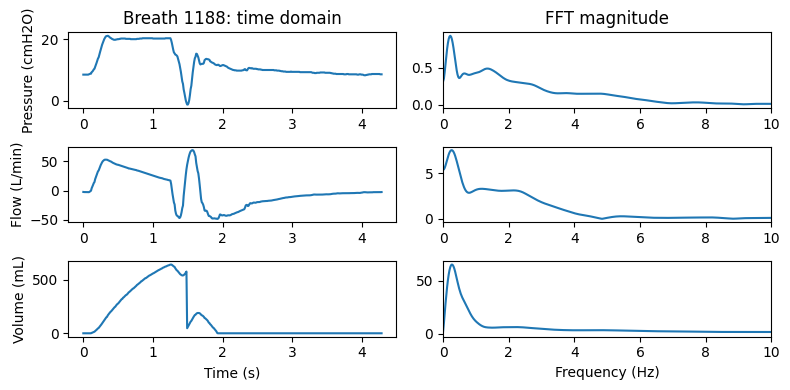

In [57]:
plot_breath_fft(breaths, 1188)

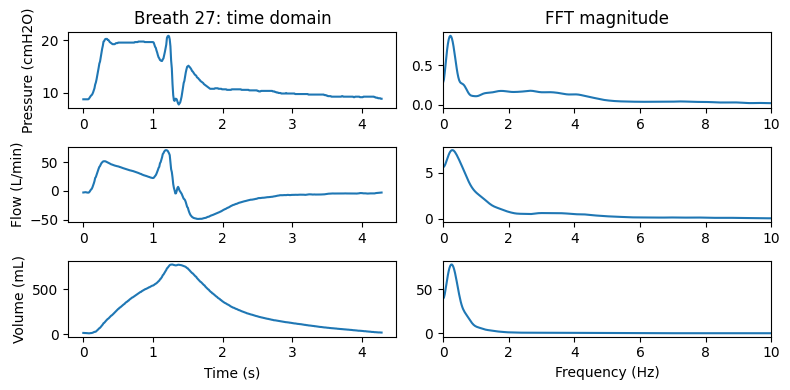

In [58]:
plot_breath_fft(breaths, 27)

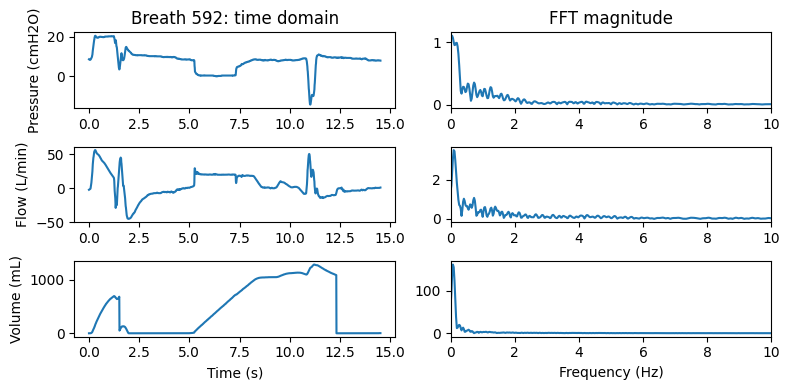

In [59]:
plot_breath_fft(breaths, 592)

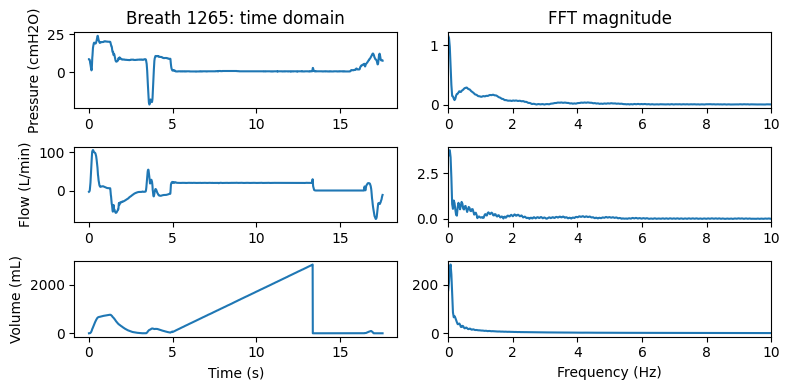

In [62]:
plot_breath_fft(breaths, 1265)

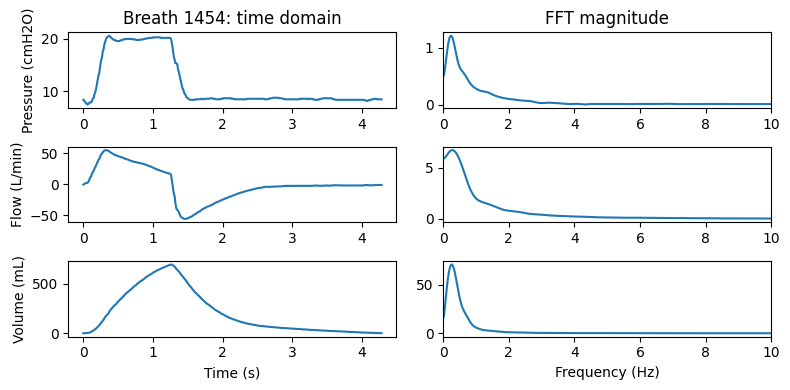

In [65]:
plot_breath_fft(breaths, 1454)

In [28]:
import numpy as np, pywt
import matplotlib.pyplot as plt

fs = 100
wavelet = "cmor1.5-1.0"                    # 複數 Morlet,適合看時頻能量
freqs = np.linspace(0.15, 15, 100)          # 想看的頻率範圍 (Hz)
scales = pywt.central_frequency(wavelet) * fs / freqs   # 頻率換成 scale

def plot_breath_cwt(breaths, bid, vmax_pct=99):
    b = breaths[bid]
    tt = b["Time (s)"].values - b["Time (s)"].values[0]
    fig, ax = plt.subplots(3, 2, figsize=(8, 4))
    for i, name in enumerate(["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]):
        x = b[name].values
        coef, f = pywt.cwt(x - x.mean(), scales, wavelet, sampling_period=1/fs)
        mag = np.abs(coef)
        ax[i, 0].plot(tt, x); ax[i, 0].set_ylabel(name)
        ax[i, 1].pcolormesh(tt, f, mag, shading="auto", cmap="viridis",
                            vmax=np.percentile(mag, vmax_pct))   # 避免低頻把顏色壓扁
        ax[i, 1].set_ylabel("Hz")
    ax[-1, 0].set_xlabel("Time (s)"); ax[-1, 1].set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()

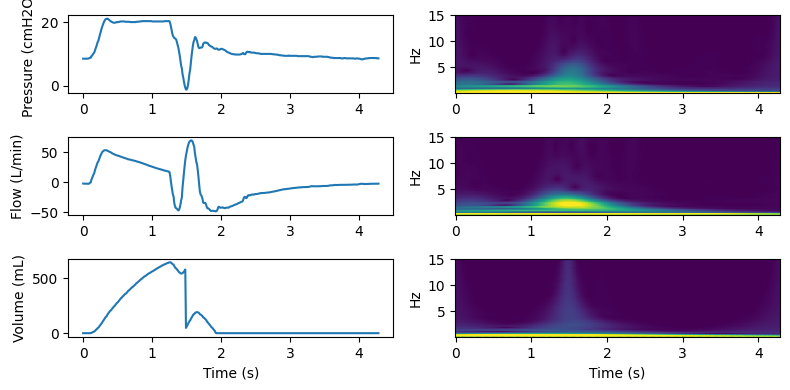

In [30]:
plot_breath_cwt(breaths, 1188)

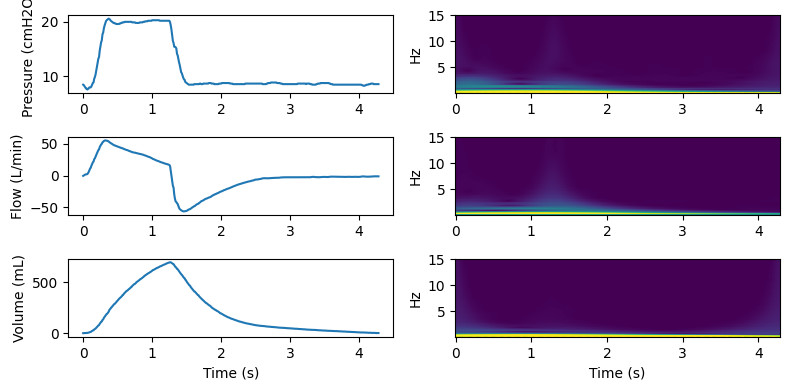

In [32]:
plot_breath_cwt(breaths, 1454)

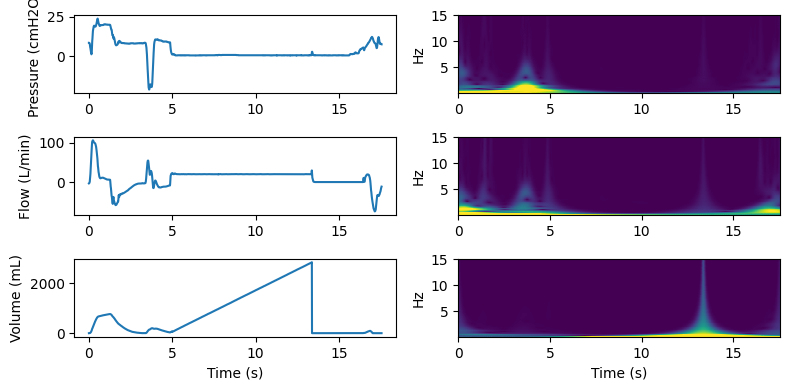

In [34]:
plot_breath_cwt(breaths, 1265)

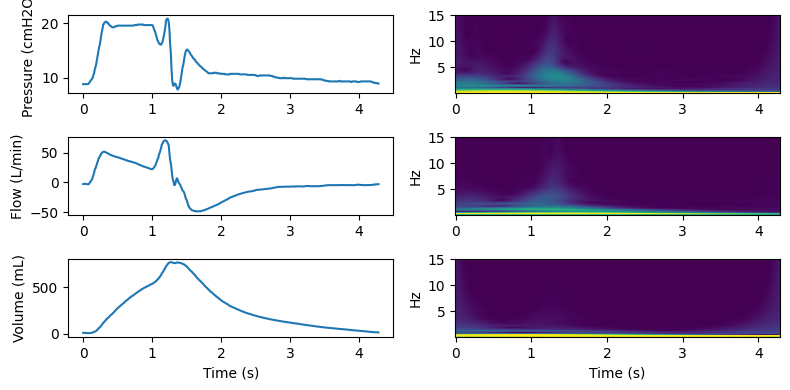

In [36]:
plot_breath_cwt(breaths, 27)